In [1]:
STATION = "BRASILIA"          # ESTACAO_NOME, e.g. "CUIABA", "MANAUS", "PORTO ALEGRE - JARDIM BOTANICO"
WET_DAY_MM = 1.0              # threshold for a wet day
SEASON = ("2024-10-01", "2025-04-30")   # test-period window for the forecast plots
SAVE_FIGURES = True

In [2]:
import sys
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import config
from inmet.io import read_dataset

INK, BODY, GRID = "#14213D", "#3E4A5C", "#D9DEE5"
BLUE, ORANGE, RED, PALE = "#2F6DB5", "#C46A1B", "#B83A3A", "#AEB9C7"
plt.rcParams.update({
    "font.size": 13, "axes.edgecolor": BODY, "axes.labelcolor": INK,
    "xtick.color": BODY, "ytick.color": BODY, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "axes.axisbelow": True, "legend.frameon": False,
})
LABELS = {"PREC": "Prec (mm)", "PMED": "P (mB)", "TMAX": "Tmax (°C)", "TMIN": "Tmin (°C)",
          "UMED": "RH mean (%)", "UMIN": "RH min (%)", "VEL": "Wind (m/s)"}
FIG_DIR = config.FIG_OUT / "stations" / STATION.replace(" ", "_")


def show(fig, name):
    if SAVE_FIGURES:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIG_DIR / name, dpi=170, bbox_inches="tight")
    plt.show()

## 1. Data and summary

In [3]:
df = read_dataset(config.CLEAN_FILE)
st = df[df[config.STATION_COL] == STATION].set_index(config.DATE_COL).sort_index()
assert not st.empty, f"{STATION} not found"
full = st.reindex(pd.date_range(config.START_DATE, config.END_DATE, freq="D"))
prec = full[config.TARGET_COL]
missing = prec.isna()
valid = prec.dropna()
split = pd.Timestamp(config.SPLIT_DATE)
variables = [config.TARGET_COL] + config.MET_VARS


def longest_dry_spell(p):
    dry = p.fillna(0) < WET_DAY_MM
    return int(dry.groupby((~dry).cumsum()).sum().max())


summary = pd.Series({
    "code": st[config.CODE_COL].iloc[0],
    "latitude": st["LATITUDE"].iloc[0],
    "longitude": st["LONGITUDE"].iloc[0],
    "days without rainfall data": f"{missing.mean():.1%}",
    "  ... in the test period": f"{missing[missing.index >= split].mean():.1%}",
    f"dry days (< {WET_DAY_MM} mm)": f"{(valid < WET_DAY_MM).mean():.1%}",
    "mean annual rainfall (mm)": round(valid.resample("YE").sum().mean()),
    "wettest day (mm)": f"{valid.max():.1f} on {valid.idxmax():%Y-%m-%d}",
    "95th percentile of wet days (mm)": round(valid[valid >= WET_DAY_MM].quantile(0.95), 1),
    "longest dry spell (days)": longest_dry_spell(prec),
}, name=STATION)
display(summary.to_frame())
display((full[variables].isna().mean() * 100).round(1).rename("% missing").to_frame().T)

,BRASILIA
code,A001
latitude,-15.789444
longitude,-47.925833
days without rainfall data,0.1%
... in the test period,0.0%
dry days (< 1.0 mm),72.4%
mean annual rainfall (mm),1297
wettest day (mm),104.8 on 2022-11-16
95th percentile of wet days (mm),43.6
longest dry spell (days),169


,PREC,PMED,TMAX,TMIN,UMED,UMIN,VEL
% missing,0.1,0.8,0.1,0.1,0.8,0.7,0.8


## 2. Daily rainfall and missing data

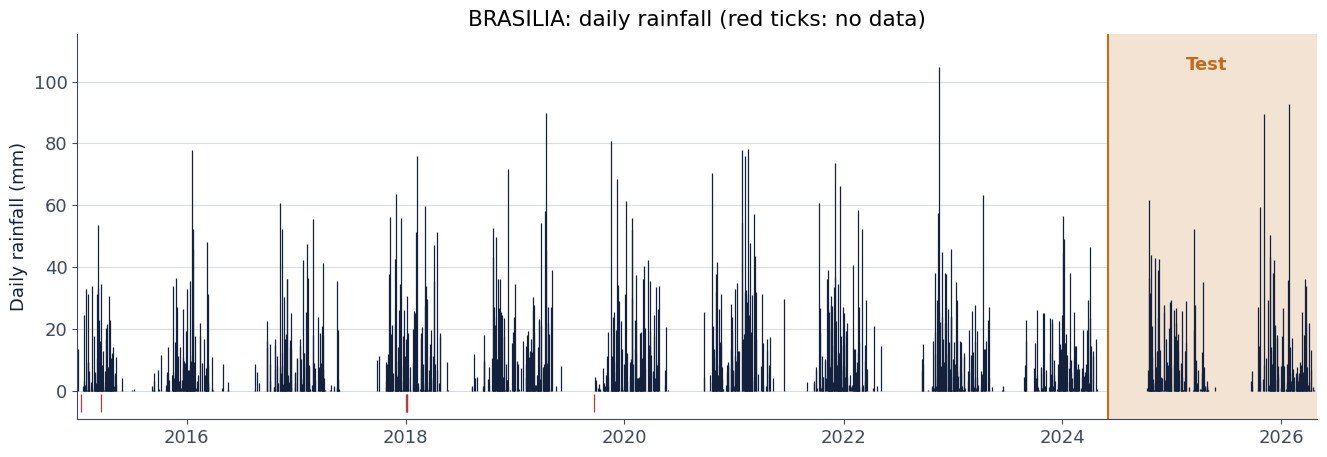

In [4]:
fig, ax = plt.subplots(figsize=(16, 5))
top = prec.max() * 1.1
ax.axvspan(split, prec.index.max(), color="#F3E3D3", lw=0)
ax.vlines(prec.index, 0, prec.fillna(0), color=INK, lw=0.9)
ax.vlines(prec.index[missing], -top * 0.06, -top * 0.01, color=RED, lw=0.9)
ax.axvline(split, color=ORANGE, lw=1.5)
ax.text(split + pd.Timedelta(days=330), top * 0.9, "Test", ha="center", color=ORANGE, fontweight="bold")
ax.set_ylim(-top * 0.08, top)
ax.set_xlim(prec.index.min(), prec.index.max())
ax.set_ylabel("Daily rainfall (mm)")
ax.set_title(f"{STATION}: daily rainfall (red ticks: no data)")
ax.grid(axis="x", visible=False)
show(fig, "series.png")

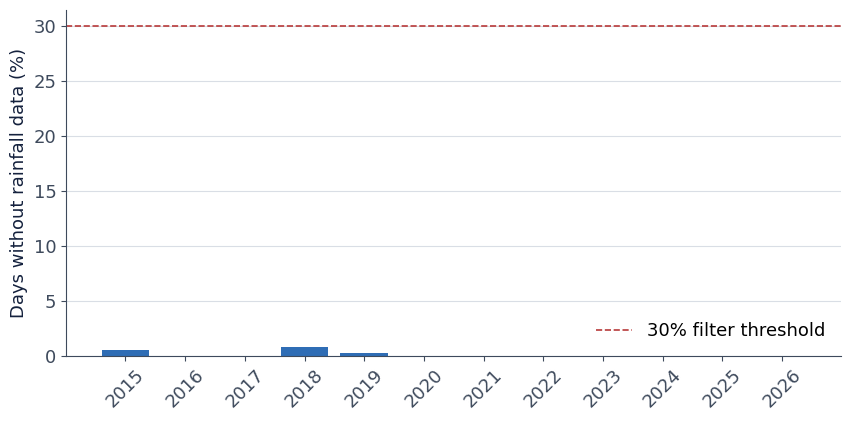

In [5]:
by_year = missing.groupby(missing.index.year).mean() * 100
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(by_year.index, by_year.values, color=[ORANGE if y >= split.year else BLUE for y in by_year.index])
ax.axhline(30, color=RED, ls="--", lw=1.2, label="30% filter threshold")
ax.set_ylabel("Days without rainfall data (%)")
ax.set_xticks(by_year.index)
ax.tick_params(axis="x", rotation=45)
ax.legend()
ax.grid(axis="x", visible=False)
show(fig, "missing_by_year.png")

## 3. All variables

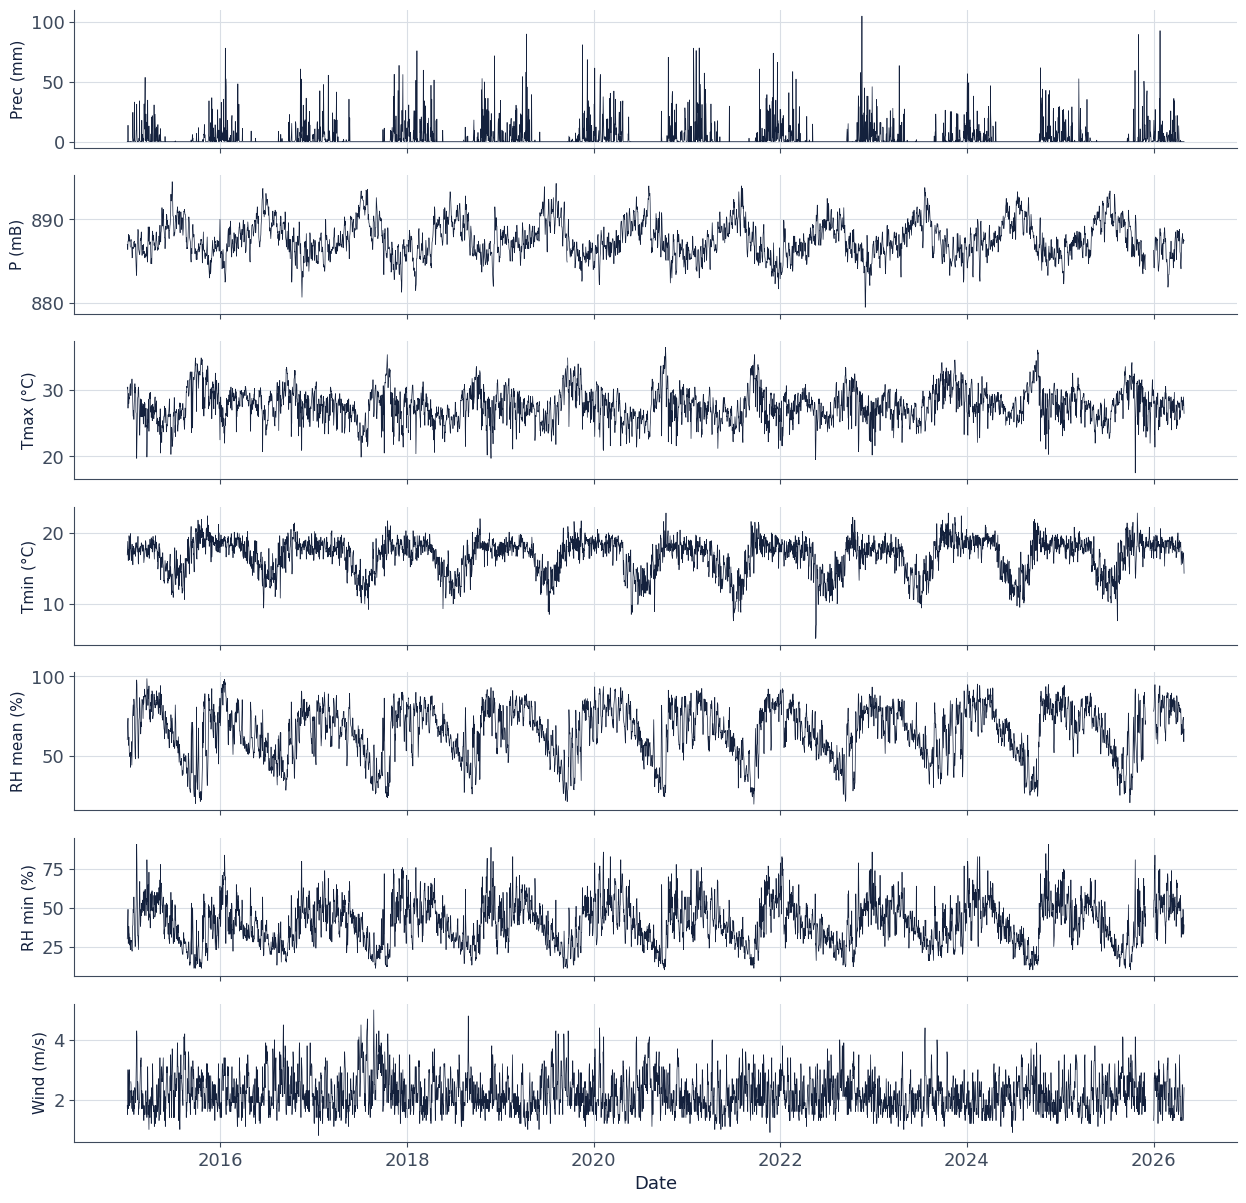

In [6]:
fig, axes = plt.subplots(len(variables), 1, figsize=(15, 2.1 * len(variables)), sharex=True)
for ax, var in zip(axes, variables):
    ax.plot(full.index, full[var], lw=0.5, color=INK)
    ax.set_ylabel(LABELS[var], fontsize=11)
axes[-1].set_xlabel("Date")
show(fig, "time_series.png")

## 4. Seasonal cycle and rainfall distribution

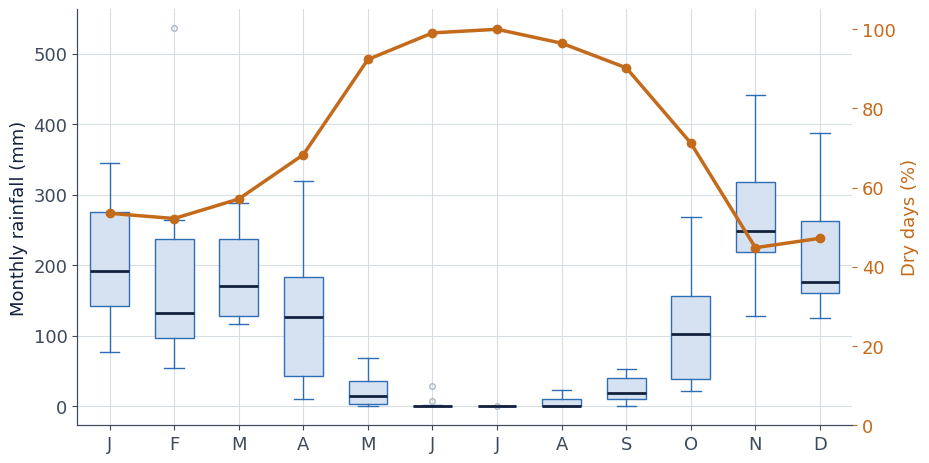

In [7]:
monthly = prec.resample("MS").sum(min_count=25)
groups = [monthly[monthly.index.month == m].dropna() for m in range(1, 13)]
dry = valid.lt(WET_DAY_MM).groupby(valid.index.month).mean() * 100
fig, ax = plt.subplots(figsize=(10, 5.4))
ax.boxplot(groups, widths=0.6, patch_artist=True,
           boxprops=dict(facecolor="#D6E2F1", color=BLUE), medianprops=dict(color=INK, lw=2),
           whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE),
           flierprops=dict(markeredgecolor=PALE, markersize=4))
ax.set_xticks(range(1, 13), list("JFMAMJJASOND"))
ax.set_ylabel("Monthly rainfall (mm)")
ax2 = ax.twinx()
ax2.plot(range(1, 13), dry.reindex(range(1, 13)), "o-", color=ORANGE, lw=2.5)
ax2.set_ylim(0, 105)
ax2.set_ylabel("Dry days (%)", color=ORANGE)
ax2.tick_params(axis="y", colors=ORANGE)
ax2.grid(False)
show(fig, "climatology.png")

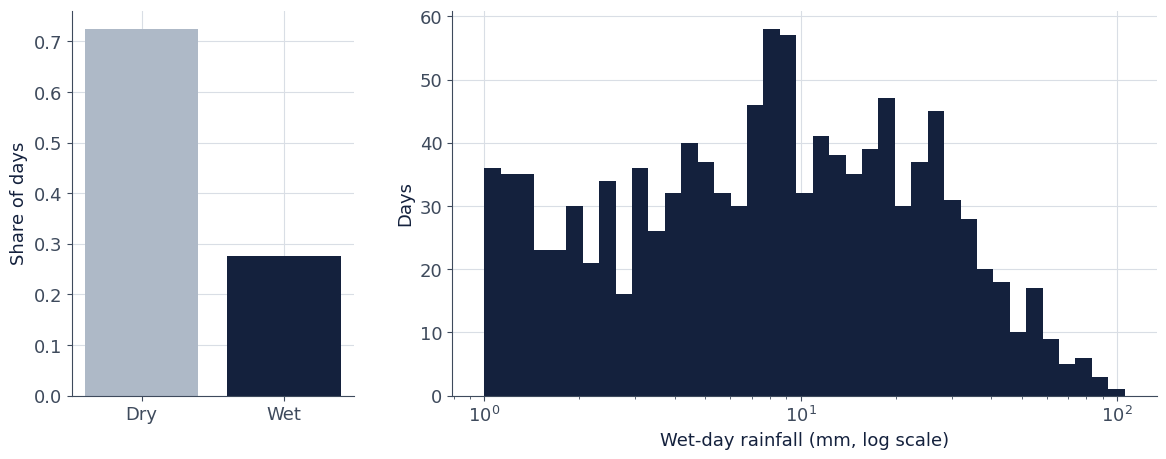

In [8]:
wet = valid[valid >= WET_DAY_MM]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 2.5]})
share = (valid < WET_DAY_MM).mean()
ax1.bar(["Dry", "Wet"], [share, 1 - share], color=[PALE, INK])
ax1.set_ylabel("Share of days")
ax2.hist(wet, bins=np.logspace(0, np.log10(wet.max() + 1), 40), color=INK)
ax2.set_xscale("log")
ax2.set_xlabel("Wet-day rainfall (mm, log scale)")
ax2.set_ylabel("Days")
show(fig, "rain_distribution.png")

## 5. Relations between rainfall and the inputs

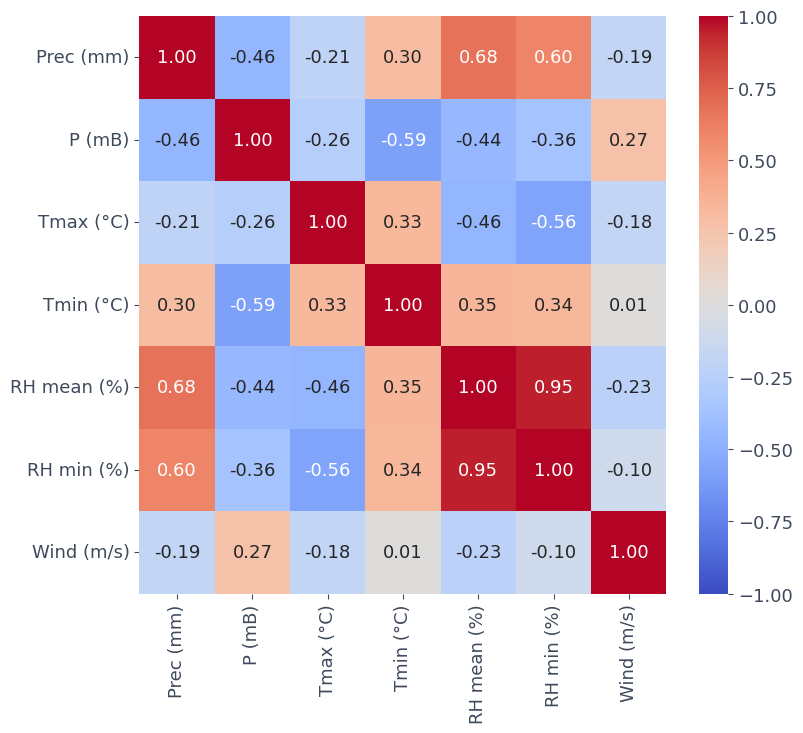

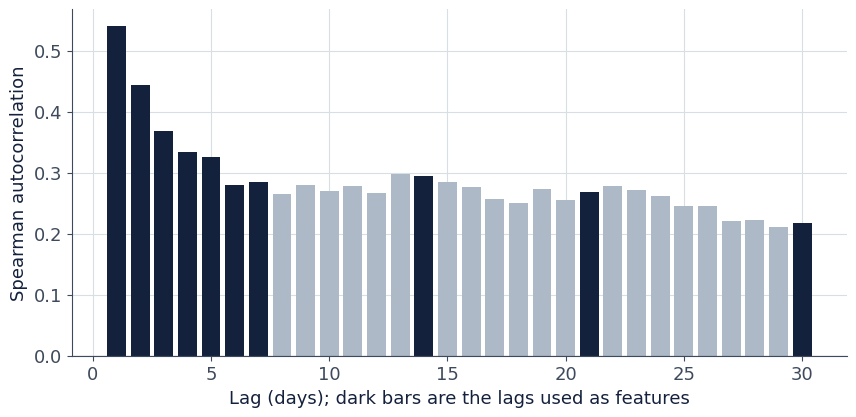

In [9]:
corr = full[variables].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.5, 7.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            xticklabels=[LABELS[v] for v in variables], yticklabels=[LABELS[v] for v in variables], ax=ax)
show(fig, "correlation.png")

lags = range(1, 31)
acf = [prec.corr(prec.shift(l), method="spearman") for l in lags]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(lags, acf, color=[INK if l in config.RAIN_LAGS else PALE for l in lags])
ax.axhline(0, color=BODY, lw=0.8)
ax.set_xlabel("Lag (days); dark bars are the lags used as features")
ax.set_ylabel("Spearman autocorrelation")
show(fig, "lag_correlation.png")

## 6. Test-period forecasts

Shown for each setup whose predictions exist: `models` (same-day inputs, as in the paper)
and `models_strict` (inputs up to day t-1). Shaded days had no rainfall data and count as 0 mm.

In [ ]:
SETUPS = {"same-day inputs": "models", "inputs up to day t-1": "models_strict"}
COLORS = [BLUE, ORANGE, "#5C9C8E", "#6B7A90", "#1F4E8C", "#7FA6D6", "#B07CC6"]

for label, folder in SETUPS.items():
    pred_file = config.RESULTS_OUT / folder / STATION.replace(" ", "_") / "predictions.csv"
    if not pred_file.exists():
        print(f"{label}: no predictions yet ({pred_file})")
        continue
    metrics = pd.read_csv(pred_file.with_name("metrics.csv")).set_index("Model")
    print(f"{label}: test-period metrics (mm)")
    display(metrics[["MAE", "RMSE"]].sort_values("RMSE").round(2).T)

    p = pd.read_csv(pred_file, parse_dates=["DATE"]).set_index("DATE")
    learned = [m for m in metrics.sort_values("RMSE").index
               if m in p.columns and m not in ("Always dry", "Persistence", "Train mean", "Climatology")]
    show_models = learned[:2] + (["Climatology"] if "Climatology" in p.columns else [])
    w = p.loc[SEASON[0]:SEASON[1]]
    gaps = missing.reindex(w.index).fillna(False)
    fig, ax = plt.subplots(figsize=(16, 5))
    for day in w.index[gaps]:
        ax.axvspan(day - pd.Timedelta(hours=12), day + pd.Timedelta(hours=12), color="#F6DADA", lw=0)
    ax.bar(w.index, w.OBSERVED, width=0.9, color=PALE, lw=0, label="Observed")
    for m, c in zip(show_models, COLORS):
        ax.plot(w.index, w[m], color=c, lw=2, ls="--" if m == "Climatology" else "-", label=m)
    ax.set_ylabel("Daily rainfall (mm)")
    ax.set_title(f"{STATION}: test period, {label}")
    ax.set_xlim(w.index.min(), w.index.max())
    ax.legend(loc="upper right", ncol=len(show_models) + 1)
    ax.grid(axis="x", visible=False)
    show(fig, f"test_forecast_{folder}.png")

same-day inputs: test-period metrics (mm)


Model,Random Forest,XGBoost,LightGBM,LSTM,RC,ARIMAX,Climatology,Train mean,Always dry,Persistence
MAE,3.15,3.19,3.22,3.30,3.34,3.30,4.71,5.44,3.39,4.77
RMSE,8.34,8.36,8.38,8.78,8.86,8.99,9.14,9.56,10.13,12.25


KeyError: "['Xgboost'] not in index"